<a href="https://colab.research.google.com/github/Janpu-Hou/Green-Learning-Basic/blob/main/process_sprSound.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

# 1. 彈出瀏覽器檔案選擇器
uploaded = files.upload()

Saving 40069321_15.3_0_p1_981.json to 40069321_15.3_0_p1_981.json


In [3]:
import shutil
import os
from google.colab import drive

# 1. 掛載 Google 雲端硬碟
drive.mount('/content/drive')

source_dir = '/content/drive/MyDrive/train_wav'
target_dir = '/content/my_dataset'

# 如果 Colab 本地已經有同名資料夾，先刪除以防衝突
if os.path.exists(target_dir):
    shutil.rmtree(target_dir)

# 2. 確保來源資料夾存在後再複製
if os.path.exists(source_dir):
    shutil.copytree(source_dir, target_dir)
    print(f"🎉 資料夾已成功複製到 Colab 本地磁碟：{target_dir}")
else:
    print(f"❌ 錯誤：找不到來源路徑 {source_dir}，請確認該資料夾確實存在於您的 Google 雲端硬碟中。")

MessageError: Error: credential propagation was unsuccessful

In [4]:
import shutil
import os
from google.colab import drive

# 1. 掛載 Google 雲端硬碟
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
source_dir = '/content/drive/MyDrive/train_wav'
target_dir = '/content/my_dataset'

In [6]:
 2. 確保來源資料夾存在後再複製
if os.path.exists(source_dir):
    shutil.copytree(source_dir, target_dir)
    print(f"🎉 資料夾已成功複製到 Colab 本地磁碟：{target_dir}")
else:
    print(f"❌ 錯誤：找不到來源路徑 {source_dir}，請確認該資料夾確實存在於您的 Google 雲端硬碟中。")

SyntaxError: invalid syntax (4056139340.py, line 1)

In [9]:
source_dir = '/content/drive/MyDrive/sprSound/train_json'
target_dir = '/content/my_label'

# 2. 確保來源資料夾存在後再複製
if os.path.exists(source_dir):
    shutil.copytree(source_dir, target_dir)
    print(f"🎉 資料夾已成功複製到 Colab 本地磁碟：{target_dir}")
else:
    print(f"❌ 錯誤：找不到來源路徑 {source_dir}，請確認該資料夾確實存在於您的 Google 雲端硬碟中。")



🎉 資料夾已成功複製到 Colab 本地磁碟：/content/my_label


In [10]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

label_dir = '/content/my_label'
all_events = []

# Read all JSON files in the target directory
for filename in os.listdir(label_dir):
    if filename.endswith('.json'):
        filepath = os.path.join(label_dir, filename)
        try:
            with open(filepath, 'r', encoding='utf-8') as f:
                data = json.load(f)
                # Extract events from event_annotation list
                events = data.get('event_annotation', [])
                for event in events:
                    # Append the event details (e.g., class/label name)
                    all_events.append(event)
        except Exception as e:
            print(f"Error reading {filename}: {e}")

# Convert to DataFrame
df_events = pd.DataFrame(all_events)

if not df_events.empty:
    display(df_events.head())

    # Plot distribution of event classes
    # Note: Adjust the column name 'event_label' or 'class' depending on your JSON schema
    # We will identify potential class columns dynamically
    class_col = None
    for col in ['event_label', 'label', 'class', 'category', 'event_type']:
        if col in df_events.columns:
            class_col = col
            break

    if class_col:
        class_counts = df_events[class_col].value_counts()
        print("--- Event Class Distribution ---")
        print(class_counts)

        plt.figure(figsize=(10, 5))
        sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
        plt.title('Event Class Distribution')
        plt.xlabel('Class')
        plt.ylabel('Count')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()
    else:
        print("Columns found in JSON:", df_events.columns.tolist())
        print("Could not automatically detect the event class column. Displaying raw data instead:")
        display(df_events.describe())
else:
    print("No events found in the JSON files or event_annotation list is empty.")

,start,end,type
0,5096,6192,Normal
1,2519,3783,Normal
2,1043,2437,Normal
3,3882,5008,Normal
4,6504,7497,Normal


Columns found in JSON: ['start', 'end', 'type']
Could not automatically detect the event class column. Displaying raw data instead:


,start,end,type
count,6656,6656,6656
unique,5037,4999,7
top,7765,9199,Normal
freq,6,13,5159


--- Event Counts by Type ---


,Count
type,
Normal,5159
Fine Crackle,912
Wheeze,452
Coarse Crackle,49
Rhonchi,39
Wheeze+Crackle,30
Stridor,15



--- Event Length Statistics by Type ---


,count,mean,std,min,max
type,,,,,
Coarse Crackle,49,933.734694,295.600432,555,1881
Fine Crackle,912,953.649123,342.377097,258,4647
Normal,5159,1403.148672,589.381549,232,7152
Rhonchi,39,754.051282,252.778762,269,1261
Stridor,15,1069.266667,482.264519,434,2619
Wheeze,452,605.024336,274.938246,126,1820
Wheeze+Crackle,30,1105.333333,338.192899,458,1672


/tmp/ipykernel_2214/2166469478.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_events, x='type', y='length', palette='Set2')


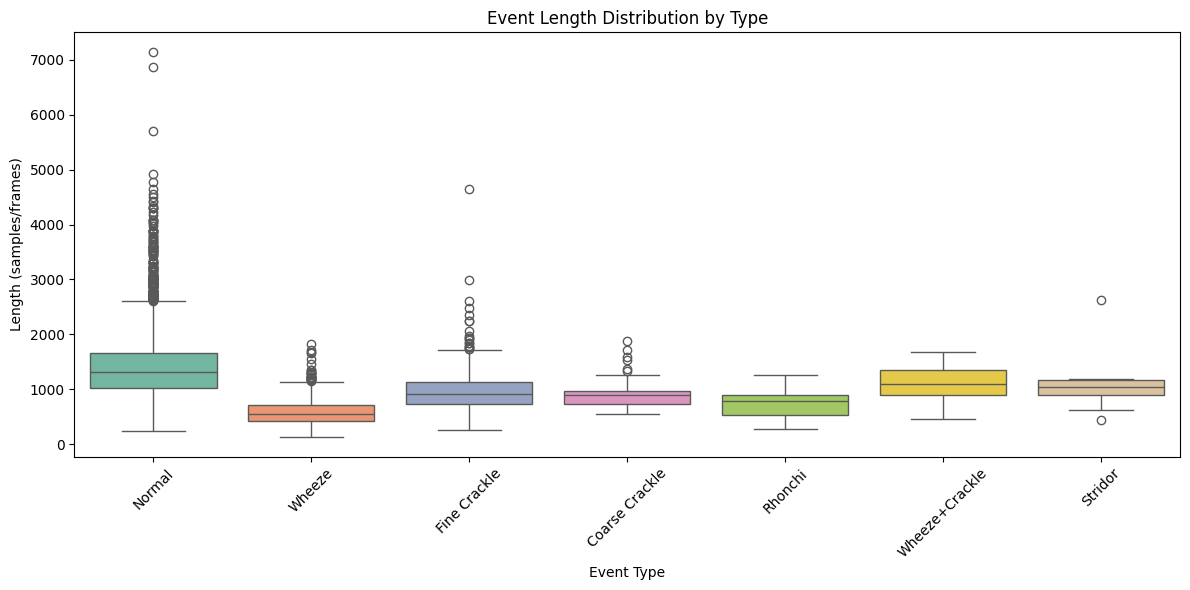

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure start and end are numeric to calculate length
df_events['start'] = pd.to_numeric(df_events['start'])
df_events['end'] = pd.to_numeric(df_events['end'])

# Calculate length for each event
df_events['length'] = df_events['end'] - df_events['start']

# 1. Show the count of each event type
type_counts = df_events['type'].value_counts()
print("--- Event Counts by Type ---")
display(type_counts.to_frame(name='Count'))

# 2. Show length statistics (mean, min, max, count) grouped by event type
length_stats = df_events.groupby('type')['length'].agg(['count', 'mean', 'std', 'min', 'max'])
print("\n--- Event Length Statistics by Type ---")
display(length_stats)

# 3. Visualize the length distribution per event type using a boxplot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_events, x='type', y='length', palette='Set2')
plt.title('Event Length Distribution by Type')
plt.xlabel('Event Type')
plt.ylabel('Length (samples/frames)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
import os
import json
import numpy as np
import scipy.io.wavfile as wav

# 定義路徑
label_dir = '/content/my_label'
wav_dir = '/content/my_dataset'
output_dir = '/content/drive/MyDrive/sprSound/event_wave'

# 確保輸出目錄存在
os.makedirs(output_dir, exist_ok=True)

print("開始進行音訊切分...")
processed_count = 0

# 逐一處理 JSON 標記檔並尋找對應的 WAV
for filename in os.listdir(label_dir):
    if filename.endswith('.json'):
        json_path = os.path.join(label_dir, filename)

        # 尋找對應的 wav 檔名（假設主檔名相同）
        base_name = os.path.splitext(filename)[0]
        wav_filename = f"{base_name}.wav"
        wav_path = os.path.join(wav_dir, wav_filename)

        # 確保 WAV 檔案存在才進行處理
        if not os.path.exists(wav_path):
            continue

        try:
            # 讀取音訊檔案
            sr, y = wav.read(wav_path)

            # 讀取 JSON 事件
            with open(json_path, 'r', encoding='utf-8') as f:
                data = json.load(f)
                events = data.get('event_annotation', [])

                for idx, event in enumerate(events):
                    event_type = event.get('type', 'Unknown')
                    # 去除檔名不允許的特殊字元
                    clean_type = event_type.replace('/', '_').replace(' ', '_')

                    # 取得 start 與 end (此處假設 start, end 單位為 sample 點)
                    start_sample = int(float(event['start']))
                    end_sample = int(float(event['end']))

                    # 避免索引超出合理範圍
                    start_sample = max(0, start_sample)
                    end_sample = min(len(y), end_sample)

                    if start_sample >= end_sample:
                        continue

                    # 切片音訊
                    y_cut = y[start_sample:end_sample]

                    # 產生新檔名：[類別名]_[原檔名]_[事件索引].wav
                    new_filename = f"{clean_type}_{base_name}_{idx}.wav"
                    new_filepath = os.path.join(output_dir, new_filename)

                    # 寫入切分後的檔案
                    wav.write(new_filepath, sr, y_cut)
                    processed_count += 1

        except Exception as e:
            print(f"處理檔案 {base_name} 時發生錯誤: {e}")

print(f"🎉 切分完成！共生成 {processed_count} 個事件音訊檔案，已儲存至：{output_dir}")

開始進行音訊切分...
處理檔案 64783073_1.3_0_p2_3270 時發生錯誤: WAV header is invalid: nAvgBytesPerSec must equal product of nSamplesPerSec and nBlockAlign, but file has nSamplesPerSec = 8000, nBlockAlign = 4, and nAvgBytesPerSec = 16000
處理檔案 65094564_5.2_1_p2_2195 時發生錯誤: WAV header is invalid: nAvgBytesPerSec must equal product of nSamplesPerSec and nBlockAlign, but file has nSamplesPerSec = 8000, nBlockAlign = 4, and nAvgBytesPerSec = 16000
處理檔案 41186340_6.6_0_p3_3199 時發生錯誤: WAV header is invalid: nAvgBytesPerSec must equal product of nSamplesPerSec and nBlockAlign, but file has nSamplesPerSec = 8000, nBlockAlign = 4, and nAvgBytesPerSec = 16000
處理檔案 41056868_2.5_1_p3_3231 時發生錯誤: WAV header is invalid: nAvgBytesPerSec must equal product of nSamplesPerSec and nBlockAlign, but file has nSamplesPerSec = 8000, nBlockAlign = 4, and nAvgBytesPerSec = 16000
處理檔案 41050041_5.6_0_p2_1699 時發生錯誤: WAV header is invalid: nAvgBytesPerSec must equal product of nSamplesPerSec and nBlockAlign, but file has nSamplesPer

In [13]:
import os
import json
import librosa
import soundfile as sf

# 定義路徑
label_dir = '/content/my_label'
wav_dir = '/content/my_dataset'
output_dir = '/content/drive/MyDrive/sprSound/event_wave'

# 確保輸出目錄存在
os.makedirs(output_dir, exist_ok=True)

print("開始使用 librosa 進行音訊切分（相容非標準 WAV 標頭）...")
processed_count = 0
error_count = 0

# 逐一處理 JSON 標記檔並尋找對應的 WAV
for filename in os.listdir(label_dir):
    if filename.endswith('.json'):
        json_path = os.path.join(label_dir, filename)

        # 尋找對應的 wav 檔名（假設主檔名相同）
        base_name = os.path.splitext(filename)[0]
        wav_filename = f"{base_name}.wav"
        wav_path = os.path.join(wav_dir, wav_filename)

        # 確保 WAV 檔案存在才進行處理
        if not os.path.exists(wav_path):
            continue

        try:
            # 使用 librosa 讀取音訊（sr=None 表示保留原始取樣率，避免重新取樣）
            y, sr = librosa.load(wav_path, sr=None)

            # 讀取 JSON 事件
            with open(json_path, 'r', encoding='utf-8') as f:
                data = json.load(f)
                events = data.get('event_annotation', [])

                for idx, event in enumerate(events):
                    event_type = event.get('type', 'Unknown')
                    # 去除檔名不允許的特殊字元
                    clean_type = event_type.replace('/', '_').replace(' ', '_')

                    # 取得 start 與 end (此處假設 start, end 單位為 sample 點)
                    start_sample = int(float(event['start']))
                    end_sample = int(float(event['end']))

                    # 避免索引超出合理範圍
                    start_sample = max(0, start_sample)
                    end_sample = min(len(y), end_sample)

                    if start_sample >= end_sample:
                        continue

                    # 切片音訊
                    y_cut = y[start_sample:end_sample]

                    # 產生新檔名：[類別名]_[原檔名]_[事件索引].wav
                    new_filename = f"{clean_type}_{base_name}_{idx}.wav"
                    new_filepath = os.path.join(output_dir, new_filename)

                    # 寫入切分後的檔案
                    sf.write(new_filepath, y_cut, sr)
                    processed_count += 1

        except Exception as e:
            error_count += 1
            if error_count <= 5:
                print(f"處理檔案 {base_name} 時發生錯誤: {e}")
            elif error_count == 6:
                print("還有其他檔案發生錯誤，後續錯誤訊息將省略...")

print(f"🎉 切分完成！共成功生成 {processed_count} 個事件音訊檔案，已儲存至：{output_dir}")

開始使用 librosa 進行音訊切分（相容非標準 WAV 標頭）...
🎉 切分完成！共成功生成 6656 個事件音訊檔案，已儲存至：/content/drive/MyDrive/sprSound/event_wave


In [14]:
import os
import json
import librosa
import soundfile as sf

# 定義路徑
label_dir = '/content/my_label'
wav_dir = '/content/my_dataset'
output_dir = '/content/drive/MyDrive/sprSound/event_wave'

# 確保輸出目錄存在
os.makedirs(output_dir, exist_ok=True)

print("開始使用 librosa 進行音訊切分（自動過濾長度超過 2 秒的事件）...")
processed_count = 0
skipped_count = 0
error_count = 0

# 逐一處理 JSON 標記檔並尋找對應的 WAV
for filename in os.listdir(label_dir):
    if filename.endswith('.json'):
        json_path = os.path.join(label_dir, filename)

        # 尋找對應的 wav 檔名
        base_name = os.path.splitext(filename)[0]
        wav_filename = f"{base_name}.wav"
        wav_path = os.path.join(wav_dir, wav_filename)

        # 確保 WAV 檔案存在才進行處理
        if not os.path.exists(wav_path):
            continue

        try:
            # 使用 librosa 讀取音訊（sr=None 表示保留原始取樣率，此處為 8000 Hz）
            y, sr = librosa.load(wav_path, sr=None)

            # 讀取 JSON 事件
            with open(json_path, 'r', encoding='utf-8') as f:
                data = json.load(f)
                events = data.get('event_annotation', [])

                for idx, event in enumerate(events):
                    event_type = event.get('type', 'Unknown')
                    # 去除檔名不允許的特殊字元
                    clean_type = event_type.replace('/', '_').replace(' ', '_')

                    # 取得 start 與 end
                    start_sample = int(float(event['start']))
                    end_sample = int(float(event['end']))

                    # 避免索引超出合理範圍
                    start_sample = max(0, start_sample)
                    end_sample = min(len(y), end_sample)

                    if start_sample >= end_sample:
                        continue

                    # 檢查事件長度：若超過 2 秒則捨棄 (2 秒 * 取樣率 sr)
                    duration_samples = end_sample - start_sample
                    if duration_samples > 2 * sr:
                        skipped_count += 1
                        continue

                    # 切片音訊
                    y_cut = y[start_sample:end_sample]

                    # 產生新檔名：[類別名]_[原檔名]_[事件索引].wav
                    new_filename = f"{clean_type}_{base_name}_{idx}.wav"
                    new_filepath = os.path.join(output_dir, new_filename)

                    # 寫入切分後的檔案
                    sf.write(new_filepath, y_cut, sr)
                    processed_count += 1

        except Exception as e:
            error_count += 1
            if error_count <= 5:
                print(f"處理檔案 {base_name} 時發生錯誤: {e}")
            elif error_count == 6:
                print("還有其他檔案發生錯誤，後續錯誤訊息將省略...")

print(f"🎉 切分完成！")
print(f"- 成功生成並儲存：{processed_count} 個事件檔案")
print(f"- 因超過 2 秒而被過濾：{skipped_count} 個事件")
print(f"- 輸出路徑：{output_dir}")

開始使用 librosa 進行音訊切分（自動過濾長度超過 2 秒的事件）...
🎉 切分完成！
- 成功生成並儲存：6656 個事件檔案
- 因超過 2 秒而被過濾：0 個事件
- 輸出路徑：/content/drive/MyDrive/sprSound/event_wave


In [15]:
import os
import numpy as np
import pandas as pd
import librosa

# 設定路徑
wav_dir = '/content/drive/MyDrive/sprSound/event_wave'
target_sr = 8000
max_length_samples = 2 * target_sr  # 2 秒 = 16000 點

X_data = []
y_data = []
filenames_list = []

print("開始載入音訊、歸一化與補零對齊...")
wav_files = [f for f in os.listdir(wav_dir) if f.endswith('.wav')]
total_files = len(wav_files)

for idx, filename in enumerate(wav_files):
    filepath = os.path.join(wav_dir, filename)

    try:
        # 1. 讀取音訊
        y, sr = librosa.load(filepath, sr=target_sr)

        # 2. 最大振幅歸一化 to 1.0 (避免除以 0)
        max_val = np.max(np.abs(y))
        if max_val > 0:
            y = y / max_val

        # 3. 補零（Padding 0）至剛好 2 秒長度 (16000 點)
        if len(y) < max_length_samples:
            padding_needed = max_length_samples - len(y)
            y = np.pad(y, (0, padding_needed), mode='constant')
        elif len(y) > max_length_samples:
            y = y[:max_length_samples]  # 防萬一，若超出則截斷

        X_data.append(y)

        # 4. 提取類別標籤（檔名第一個下底線前之部分，例如 'Normal_...' -> 'Normal'）
        label = filename.split('_')[0]
        y_data.append(label)
        filenames_list.append(filename)

        if (idx + 1) % 1000 == 0 or (idx + 1) == total_files:
            print(f"已處理 {idx + 1} / {total_files} 個檔案")

    except Exception as e:
        print(f"處理 {filename} 時發生錯誤: {e}")

# 轉為 numpy array
X_array = np.array(X_data)
y_array = np.array(y_data)

# 5. 儲存為 CSV 檔案
# 每列代表一個音訊檔案的 16000 個採樣點
X_csv_path = '/content/drive/MyDrive/sprSound/X_wave.csv'
y_csv_path = '/content/drive/MyDrive/sprSound/y_label.csv'

print("正在寫入 CSV 檔案至 Google Drive，這可能需要幾分鐘時間...")
pd.DataFrame(X_array).to_csv(X_csv_path, index=False, header=False)
pd.DataFrame({'label': y_array, 'filename': filenames_list}).to_csv(y_csv_path, index=False)

print(f"🎉 處理完成！")
print(f"- X_wave.csv 已儲存至: {X_csv_path} (維度: {X_array.shape})")
print(f"- y_label.csv 已儲存至: {y_csv_path} (維度: {y_array.shape})")

開始載入音訊、歸一化與補零對齊...
已處理 1000 / 6656 個檔案
已處理 2000 / 6656 個檔案
已處理 3000 / 6656 個檔案
已處理 4000 / 6656 個檔案
已處理 5000 / 6656 個檔案
已處理 6000 / 6656 個檔案
已處理 6656 / 6656 個檔案
正在寫入 CSV 檔案至 Google Drive，這可能需要幾分鐘時間...
🎉 處理完成！
- X_wave.csv 已儲存至: /content/drive/MyDrive/sprSound/X_wave.csv (維度: (6656, 16000))
- y_label.csv 已儲存至: /content/drive/MyDrive/sprSound/y_label.csv (維度: (6656,))


In [16]:
import os
import numpy as np
import pandas as pd
import librosa

# 設定路徑
X_csv_path = '/content/drive/MyDrive/sprSound/X_wave.csv'
output_mel_path = '/content/drive/MyDrive/sprSound/X_mel.npy'
target_sr = 8000

# 1. 讀取 X 訊號數據（優先使用記憶體中的變數以節省時間）
try:
    if 'X_array' in globals():
        print("從記憶體中載入 X_array...")
        X = X_array
    else:
        print("從 CSV 檔案載入 X_wave.csv (這可能需要一點時間)...")
        X = pd.read_csv(X_csv_path, header=None).values
except Exception as e:
    print(f"載入數據失敗: {e}")
    # 嘗試讀取 csv
    X = pd.read_csv(X_csv_path, header=None).values

print(f"資料維度: {X.shape}")

# 2. 定義 Mel-spectrogram 參數
n_fft = 1024
hop_length = 256  # 256 點對應於 8000Hz 約 32 毫秒一幀，2秒共 63 幀左右
n_mels = 128      # 128 個梅爾頻段

X_mel = []

print("開始轉換為 Mel-spectrogram...")
for idx, signal in enumerate(X):
    # 產生 Mel-spectrogram
    mel_spec = librosa.feature.melspectrogram(
        y=signal,
        sr=target_sr,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels
    )
    # 轉換為對數刻度 (dB)
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    X_mel.append(mel_spec_db)

    if (idx + 1) % 1000 == 0 or (idx + 1) == len(X):
        print(f"已處理 {idx + 1} / {len(X)} 筆音訊")

# 轉為 numpy array 格式
X_mel = np.array(X_mel)

# 3. 儲存為 .npy 格式（相較於 CSV，儲存多維矩陣速度更快且不失真）
print("正在將 Mel-spectrogram 特徵矩陣寫入 Google Drive...")
np.save(output_mel_path, X_mel)

print(f"🎉 Mel-spectrogram 轉換與儲存完成！")
print(f"- 輸出檔案路徑: {output_mel_path}")
print(f"- 輸出特徵維度 (筆數, 頻段數, 時間幀數): {X_mel.shape}")

從記憶體中載入 X_array...
資料維度: (6656, 16000)
開始轉換為 Mel-spectrogram...
已處理 1000 / 6656 筆音訊
已處理 2000 / 6656 筆音訊
已處理 3000 / 6656 筆音訊
已處理 4000 / 6656 筆音訊
已處理 5000 / 6656 筆音訊
已處理 6000 / 6656 筆音訊
已處理 6656 / 6656 筆音訊
正在將 Mel-spectrogram 特徵矩陣寫入 Google Drive...
🎉 Mel-spectrogram 轉換與儲存完成！
- 輸出檔案路徑: /content/drive/MyDrive/sprSound/X_mel.npy
- 輸出特徵維度 (筆數, 頻段數, 時間幀數): (6656, 128, 63)


=== 類別分佈與佔比統計 ===


,Count,Percentage (%)
label,,
Normal,5159,77.509014
Fine,912,13.701923
Wheeze,452,6.790865
Coarse,49,0.736178
Rhonchi,39,0.585938
Wheeze+Crackle,30,0.450721
Stridor,15,0.225361


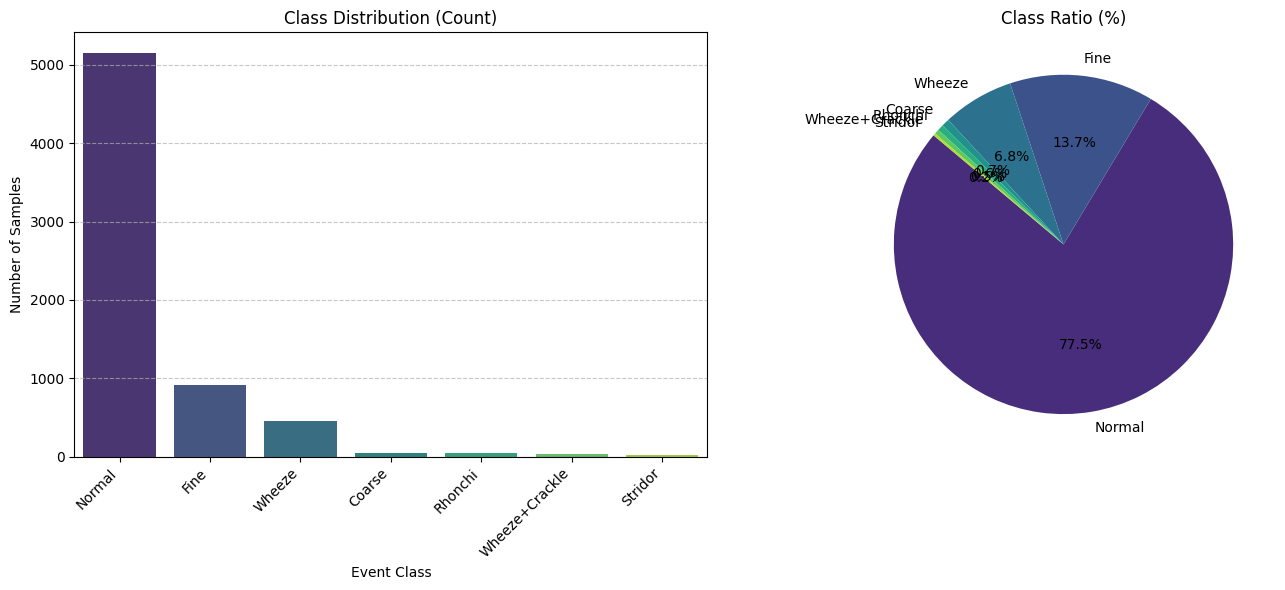

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 讀取 y_label.csv
y_csv_path = '/content/drive/MyDrive/sprSound/y_label.csv'
df_labels = pd.read_csv(y_csv_path)

# 1. 計算類別分佈與比例
class_counts = df_labels['label'].value_counts()
class_proportions = df_labels['label'].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({
    'Count': class_counts,
    'Percentage (%)': class_proportions
})

print("=== 類別分佈與佔比統計 ===")
display(dist_df)

# 2. 繪製圓餅圖與長條圖以視覺化不平衡狀況
plt.figure(figsize=(14, 6))

# 左圖：長條圖
plt.subplot(1, 2, 1)
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis', hue=class_counts.index, legend=False)
plt.title('Class Distribution (Count)')
plt.xlabel('Event Class')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 右圖：圓餅圖
plt.subplot(1, 2, 2)
plt.pie(class_counts, labels=class_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('viridis', len(class_counts)))
plt.title('Class Ratio (%)')

plt.tight_layout()
plt.show()

In [18]:
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
import os

# 設定路徑
mel_path = '/content/drive/MyDrive/sprSound/X_mel.npy'
y_path = '/content/drive/MyDrive/sprSound/y_label.csv'
output_x_path = '/content/drive/MyDrive/sprSound/X_mel_balanced.npy'
output_y_path = '/content/drive/MyDrive/sprSound/y_label_balanced.csv'

# 1. 載入資料
print("正在載入資料...")
if 'X_mel' in globals():
    X_raw = X_mel
else:
    X_raw = np.load(mel_path)

df_labels = pd.read_csv(y_path)
y_raw = df_labels['label'].values

num_samples, n_mels, n_frames = X_raw.shape
print(f"原始 X 尺寸: {X_raw.shape} (樣本數={num_samples}, 頻段={n_mels}, 時間幀={n_frames})")
print(f"原始 y 尺寸: {y_raw.shape}")

# 2. 將 3D Mel-spectrogram 展平成 2D 以進行 SMOTE
X_flat = X_raw.reshape(num_samples, -1)
print(f"展平後特徵尺寸: {X_flat.shape}")

# 3. 套用 SMOTE 進行類別平衡
print("正在執行 SMOTE 類別平衡... (這可能需要一點時間)")
smote = SMOTE(random_state=42)
X_flat_resampled, y_resampled = smote.fit_resample(X_flat, y_raw)

# 4. 將平衡後的二維特徵還原為 CNN 訓練所需的 3D 或 4D 形狀
# 轉換回 (新樣本數, 128, 63)
X_resampled_3d = X_flat_resampled.reshape(-1, n_mels, n_frames)

# 為 CNN 加上單通道(Channel)維度 -> (新樣本數, 128, 63, 1)
X_resampled_4d = np.expand_dims(X_resampled_3d, axis=-1)

print("\n=== 平衡後結果 ===")
print(f"平衡後特徵 (3D) 尺寸: {X_resampled_3d.shape}")
print(f"平衡後特徵 (CNN 4D) 尺寸: {X_resampled_4d.shape}")
print(f"平衡後標籤數量: {len(y_resampled)}")

# 5. 儲存平衡後的資料至 Google Drive
print("\n正在儲存平衡後的資料至 Google Drive...")
np.save(output_x_path, X_resampled_4d)
pd.DataFrame({'label': y_resampled}).to_csv(output_y_path, index=False)

# 6. 印出新類別分佈確認平衡狀態
unique, counts = np.unique(y_resampled, return_counts=True)
balanced_dist = pd.DataFrame({'Count': counts}, index=unique)
display(balanced_dist)
print(f"🎉 平衡特徵已儲存至: {output_x_path}")
print(f"🎉 平衡標籤已儲存至: {output_y_path}")

正在載入資料...
原始 X 尺寸: (6656, 128, 63) (樣本數=6656, 頻段=128, 時間幀=63)
原始 y 尺寸: (6656,)
展平後特徵尺寸: (6656, 8064)
正在執行 SMOTE 類別平衡... (這可能需要一點時間)

=== 平衡後結果 ===
平衡後特徵 (3D) 尺寸: (36113, 128, 63)
平衡後特徵 (CNN 4D) 尺寸: (36113, 128, 63, 1)
平衡後標籤數量: 36113

正在儲存平衡後的資料至 Google Drive...


,Count
Coarse,5159
Fine,5159
Normal,5159
Rhonchi,5159
Stridor,5159
Wheeze,5159
Wheeze+Crackle,5159


🎉 平衡特徵已儲存至: /content/drive/MyDrive/sprSound/X_mel_balanced.npy
🎉 平衡標籤已儲存至: /content/drive/MyDrive/sprSound/y_label_balanced.csv


正在載入平衡後的數據...
X 矩陣形狀: (36113, 128, 63, 1)
y 標籤長度: 36113
類別對照與對應索引:
  0: Coarse
  1: Fine
  2: Normal
  3: Rhonchi
  4: Stridor
  5: Wheeze
  6: Wheeze+Crackle

訓練集形狀: (28890, 128, 63, 1)
測試集形狀: (7223, 128, 63, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 63, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 63, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 31, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 31, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 15, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 15, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 7, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 7, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 14336)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,835,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,930,119 (7.36 MB)

 Trainable params: 1,929,415 (7.36 MB)

 Non-trainable params: 704 (2.75 KB)


開始訓練模型 (Epochs=15, Batch Size=64)...
Epoch 1/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 856s 2s/step - accuracy: 0.5353 - loss: 1.3099 - val_accuracy: 0.1827 - val_loss: 3.5399
Epoch 2/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 830s 2s/step - accuracy: 0.7251 - loss: 0.7701 - val_accuracy: 0.5152 - val_loss: 1.4144
Epoch 3/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 837s 2s/step - accuracy: 0.7837 - loss: 0.5866 - val_accuracy: 0.1458 - val_loss: 157.3147
Epoch 4/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 854s 2s/step - accuracy: 0.8148 - loss: 0.5044 - val_accuracy: 0.7442 - val_loss: 0.7155
Epoch 5/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 820s 2s/step - accuracy: 0.8315 - loss: 0.4512 - val_accuracy: 0.1466 - val_loss: 441.1928
Epoch 6/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 826s 2s/step - accuracy: 0.8425 - loss: 0.4170 - val_accuracy: 0.8636 - val_loss: 0.3614
Epoch 7/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 823s 2s/step - accuracy: 0.8536 - loss: 0.3804 - val_accuracy: 0.1429 - val_loss: 11987.9150
Epoch 8/15
452/452 ━━━━━━━━━━━━━━━━━━━━ 825s 2s/ste

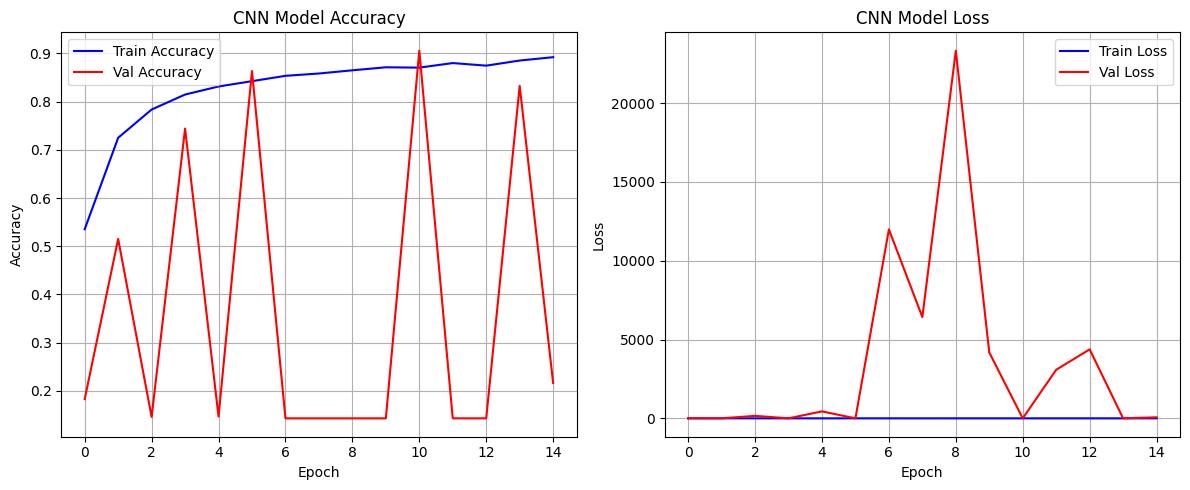


🎉 測試集評估結果:
- 測試集 Loss: 65.7967
- 測試集 Accuracy: 21.61%


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical

# 1. 載入平衡後的特徵與標籤
print("正在載入平衡後的數據...")
X_path = '/content/drive/MyDrive/sprSound/X_mel_balanced.npy'
y_path = '/content/drive/MyDrive/sprSound/y_label_balanced.csv'

X = np.load(X_path)
df_y = pd.read_csv(y_path)
y_raw = df_y['label'].values

print(f"X 矩陣形狀: {X.shape}")
print(f"y 標籤長度: {len(y_raw)}")

# 2. 類別標籤編碼 (One-Hot Encoding)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_raw)
num_classes = len(label_encoder.classes_)
y_onehot = to_categorical(y_encoded, num_classes=num_classes)

print(f"類別對照與對應索引:")
for idx, class_name in enumerate(label_encoder.classes_):
    print(f"  {idx}: {class_name}")

# 3. 分割訓練集與測試集 (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_onehot, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"\n訓練集形狀: {X_train.shape}")
print(f"測試集形狀: {X_test.shape}")

# 4. 建立 2D CNN 模型
def build_cnn_model(input_shape, num_classes):
    model = models.Sequential([
        # 第一層卷積
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape, padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # 第二層卷積
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # 第三層卷積
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        # 展平與全連接層
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

input_shape = (X.shape[1], X.shape[2], X.shape[3]) # (128, 63, 1)
model = build_cnn_model(input_shape, num_classes)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 5. 訓練模型
epochs = 15
batch_size = 64

print(f"\n開始訓練模型 (Epochs={epochs}, Batch Size={batch_size})...")
history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    verbose=1
)

# 6. 繪製訓練與驗證的準確度及損失曲線
plt.figure(figsize=(12, 5))

# 準確度 (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='b')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='r')
plt.title('CNN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 損失值 (Loss)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='b')
plt.plot(history.history['val_loss'], label='Val Loss', color='r')
plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 7. 評估測試集結果
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\n🎉 測試集評估結果:")
print(f"- 測試集 Loss: {test_loss:.4f}")
print(f"- 測試集 Accuracy: {test_acc*100:.2f}%")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# 1. 載入平衡後的特徵與標籤
print("正在載入數據...")
X_path = '/content/drive/MyDrive/sprSound/X_mel_balanced.npy'
y_path = '/content/drive/MyDrive/sprSound/y_label_balanced.csv'

X = np.load(X_path)
df_y = pd.read_csv(y_path)
y_raw = df_y['label'].values

# 2. 類別標籤編碼
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_raw)
num_classes = len(label_encoder.classes_)
y_onehot = to_categorical(y_encoded, num_classes=num_classes)

# 3. 重新分割訓練集與測試集
X_train, X_test, y_train, y_test = train_test_split(
    X, y_onehot, test_size=0.2, random_state=42, stratify=y_encoded
)

# 4. 建立更具泛化性、加入 L2 正則化的新型 2D CNN 模型
def build_fine_tuned_cnn(input_shape, num_classes):
    model = models.Sequential([
        # 輸入層
        layers.Input(shape=input_shape),

        # 第一層卷積塊
        layers.Conv2D(32, (3, 3), padding='same', kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        # 第二層卷積塊
        layers.Conv2D(64, (3, 3), padding='same', kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        # 第三層卷積塊
        layers.Conv2D(128, (3, 3), padding='same', kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.4),

        # 展平與 Dense 層
        layers.Flatten(),
        layers.Dense(256, kernel_regularizer=regularizers.l2(1e-4)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.5),

        # 輸出層
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

input_shape = (X.shape[1], X.shape[2], X.shape[3])
model = build_fine_tuned_cnn(input_shape, num_classes)

# 使用更小的學習率 (0.0005) 來穩定訓練
opt = tf.keras.optimizers.Adam(learning_rate=0.0005)

model.compile(
    optimizer=opt,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 5. 設定 Callbacks 控制超參數與收斂
# 當 5 個 epoch 內驗證損失皆未改善時即停止訓練，並回復到最佳權重
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# 當 2 個 epoch 內驗證損失未改善時，將學習率乘以 0.5
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# 儲存最佳模型檔
checkpoint_path = '/content/drive/MyDrive/sprSound/best_cnn_model.keras'
model_checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

# 6. 開始訓練
epochs = 30
batch_size = 128  # 增加 Batch Size 讓梯度更新更平滑

print(f"\n開始微調訓練 (最大 Epochs={epochs}, Batch Size={batch_size})...")
history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test, y_test),
    callbacks=[early_stopping, reduce_lr, model_checkpoint],
    verbose=1
)

# 7. 繪製精緻的 Loss & Accuracy 歷史圖表
plt.figure(figsize=(14, 5))

# 準確度 (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', color='#1f77b4', linewidth=2)
plt.plot(history.history['val_accuracy'], label='Val Accuracy', color='#d62728', linewidth=2)
plt.title('Fine-Tuned CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# 損失值 (Loss)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', color='#1f77b4', linewidth=2)
plt.plot(history.history['val_loss'], label='Val Loss', color='#d62728', linewidth=2)
plt.title('Fine-Tuned CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 8. 評估最佳模型於測試集之表現
best_model = tf.keras.models.load_model(checkpoint_path)
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f"\n🎉 微調後最佳模型評估結果:")
print(f"- 測試集 Loss: {test_loss:.4f}")
print(f"- 測試集 Accuracy: {test_acc*100:.2f}%")

正在載入數據...

開始微調訓練 (最大 Epochs=30, Batch Size=128)...
Epoch 1/30
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.2887 - loss: 2.1491
Epoch 1: val_loss improved from None to 1.78182, saving model to /content/drive/MyDrive/sprSound/best_cnn_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/sprSound/best_cnn_model.keras
226/226 ━━━━━━━━━━━━━━━━━━━━ 862s 4s/step - accuracy: 0.3461 - loss: 1.9150 - val_accuracy: 0.3393 - val_loss: 1.7818 - learning_rate: 5.0000e-04
Epoch 2/30
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.4463 - loss: 1.5445
Epoch 2: val_loss did not improve from 1.78182
226/226 ━━━━━━━━━━━━━━━━━━━━ 863s 4s/step - accuracy: 0.4703 - loss: 1.4781 - val_accuracy: 0.3697 - val_loss: 2.0573 - learning_rate: 5.0000e-04
Epoch 3/30
226/226 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5385 - loss: 1.2964
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 3: val_loss did not improve from 1.78182
226/226 ━━━━━━━━━━━━━━━━

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf

# 1. 載入平衡後的資料以取得標籤與類別對照
y_path = '/content/drive/MyDrive/sprSound/y_label_balanced.csv'
df_y = pd.read_csv(y_path)
y_raw = df_y['label'].values

label_encoder = LabelEncoder()
label_encoder.fit(y_raw)
class_names = label_encoder.classes_

# 2. 載入測試特徵與最佳模型
print("正在載入測試資料與最佳模型...")
X_path = '/content/drive/MyDrive/sprSound/X_mel_balanced.npy'
X = np.load(X_path)

# 對 y 進行編碼
y_encoded = label_encoder.transform(y_raw)

# 重新劃分出與訓練時完全一致的測試集 (random_state=42)
from sklearn.model_selection import train_test_split
_, X_test, _, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

checkpoint_path = '/content/drive/MyDrive/sprSound/best_cnn_model.keras'
best_model = tf.keras.models.load_model(checkpoint_path)

# 3. 預測測試集
print("正在進行模型預測...")
y_pred_probs = best_model.predict(X_test, batch_size=128)
y_pred = np.argmax(y_pred_probs, axis=1)

# 4. 產生混淆矩陣
cm = confusion_matrix(y_test, y_pred)
# 計算百分比格式的混淆矩陣 (按列/真實標籤標準化)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

# 5. 繪製混淆矩陣熱力圖
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Accuracy (%)'}
)

plt.title('Normalized Confusion Matrix (%) of Fine-Tuned CNN')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 6. 印出詳細的分類報告 (Precision, Recall, F1-Score)
print("\n=== 詳細分類報告 (Classification Report) ===")
print(classification_report(y_test, y_pred, target_names=class_names))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/sprSound/y_label_balanced.csv'